# First Computer Vision Project
### Reading a cricket innings from broadcast video

**The question, in plain English:** can a computer watch two and a half minutes of TV highlights and work out how an innings was built, ball by ball, and how the batter moved when he played each shot?

The video is the broadcast highlights of my innings for Thiruvallur in the S.S. Rajan Trophy (73 off 44). Four computer-vision steps turn it into data:

1. **Read the scoreboard** on every frame with OCR, to rebuild the innings ball by ball.
2. **Cut the video into camera shots** and find the ones filmed from the main delivery camera.
3. **Find the batter** in those shots with an object detector.
4. **Estimate his pose** (17 body points) in every frame, then measure each stroke.

Runtime: about 25 minutes on CPU, much less on a Colab GPU. Every step caches its output.

## 0 · Setup

Install the libraries: Ultralytics YOLO11 for detection and pose, RapidOCR and Tesseract for reading text, OpenCV for video.

In [1]:
import os, sys, json, subprocess
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    !apt-get -qq install -y tesseract-ocr > /dev/null
    !pip -q install ultralytics==8.4.* rapidocr-onnxruntime pytesseract opencv-python-headless matplotlib
    !git clone -q https://github.com/Hemanth-55/First-Computer-Vision-Project.git
    %cd First-Computer-Vision-Project

## 1 · The video

Point `VIDEO` at your copy of the highlights. In Colab, upload it with the file browser on the left. The broadcast footage is not stored in this repository.

In [2]:
VIDEO = os.environ.get('VIDEO', 'innings.mov')
import cv2
cap = cv2.VideoCapture(VIDEO)
fps, n = cap.get(cv2.CAP_PROP_FPS), int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
print(f"{int(cap.get(3))}x{int(cap.get(4))} · {n} frames · {n / fps:.1f} s")

2388x1668 · 3976 frames · 146.2 s


## 2 · Run the pipeline

One command runs all four steps and writes `outputs/metrics.json` and the charts. Steps that already have an output are skipped.

In [3]:
subprocess.run([sys.executable, 'src/run_all.py', VIDEO], check=True)
m = json.load(open('outputs/metrics.json'))
print(json.dumps(m['pipeline'], indent=1))

skip   scoreboard_raw.json
skip   timeline.json
skip   scenes.json
skip   shots.json
skip   pose_raw.json
skip   strokes_raw.json


{
 "video": {
  "seconds": 146.2,
  "frames": 3976,
  "resolution": "2388x1668",
  "source": "FanCode broadcast highlights, S.S. Rajan Trophy (TNCA inter-district T20)",
  "title_on_broadcast": "73 off 44! Hemanth Kumar G guides Thiruvallur to 177"
 },
 "pipeline": {
  "scoreboard_samples": 293,
  "scoreboard_read": 246,
  "camera_shots": 45,
  "delivery_shots": 15,
  "strokes_tracked": 9,
  "keypoints": 17
 },
 "consistency": {
  "stance_spread": 0.076,
  "contact_spread": 0.182,
  "ratio": 2.4
 }
}
phases [{'name': 'Fast start', 'from': 1, 'to': 13, 'balls': 13, 'runs': 25, 'strike_rate': 192}, {'name': 'Rebuild', 'from': 14, 'to': 24, 'balls': 11, 'runs': 9, 'strike_rate': 82}, {'name': 'Acceleration', 'from': 25, 'to': 31, 'balls': 7, 'runs': 24, 'strike_rate': 343}, {'name': 'Finish of the footage', 'from': 32, 'to': 38, 'balls': 7, 'runs': 7, 'strike_rate': 100}]
fours [4, 7, 8, 11, 13, 25] sixes [28, 30, 31]
stroke shot 1 ball 4 runs 4 1 (3)
stroke shot 3 ball 7 runs 4 6 (6)
str

figures written
done: outputs/metrics.json and figures/
{
 "scoreboard_samples": 293,
 "scoreboard_read": 246,
 "camera_shots": 45,
 "delivery_shots": 15,
 "strokes_tracked": 9,
 "keypoints": 17
}


## 3 · Check the computer's reading

OCR can misread digits, so every reading is cross-checked: Hemanth's runs and balls must never go down, and on a single ball his runs can't exceed the team's.

In [4]:
pts = m['innings']['points']
ok_monotonic = all(b['runs'] >= a['runs'] and b['balls'] >= a['balls'] for a, b in zip(pts, pts[1:]))
ok_team = all((b['team'][0] - a['team'][0]) >= (b['runs'] - a['runs']) for a, b in zip(pts, pts[1:]) if a['team'] and b['team'])
print('never decreasing:', ok_monotonic, '· consistent with team total:', ok_team)
for p in pts: print(f"ball {p['balls']:>2}  {p['runs']:>2} runs   team {p['team'][0]}-{p['team'][1]}" + (f"   <- {p['ball_runs']} off this ball" if 'ball_runs' in p else ''))

never decreasing: True · consistent with team total: True
ball  3   1 runs   team 4-0
ball  4   5 runs   team 8-0   <- 4 off this ball
ball  6   6 runs   team 11-0
ball  7  10 runs   team 15-0   <- 4 off this ball
ball  8  14 runs   team 19-0   <- 4 off this ball
ball 10  17 runs   team 27-0
ball 11  21 runs   team 31-0   <- 4 off this ball
ball 12  21 runs   team 31-0   <- 0 off this ball
ball 13  25 runs   team 35-0   <- 4 off this ball
ball 24  34 runs   team 64-1
ball 25  38 runs   team 68-1   <- 4 off this ball
ball 27  39 runs   team 77-1
ball 28  45 runs   team 83-1   <- 6 off this ball
ball 29  46 runs   team 86-1   <- 1 off this ball
ball 30  52 runs   team 92-1   <- 6 off this ball
ball 31  58 runs   team 99-1   <- 6 off this ball
ball 38  65 runs   team 109-1


## 4 · How the innings was built

Runs against balls faced. Blue dots are boundaries the scoreboard confirms ball by ball.

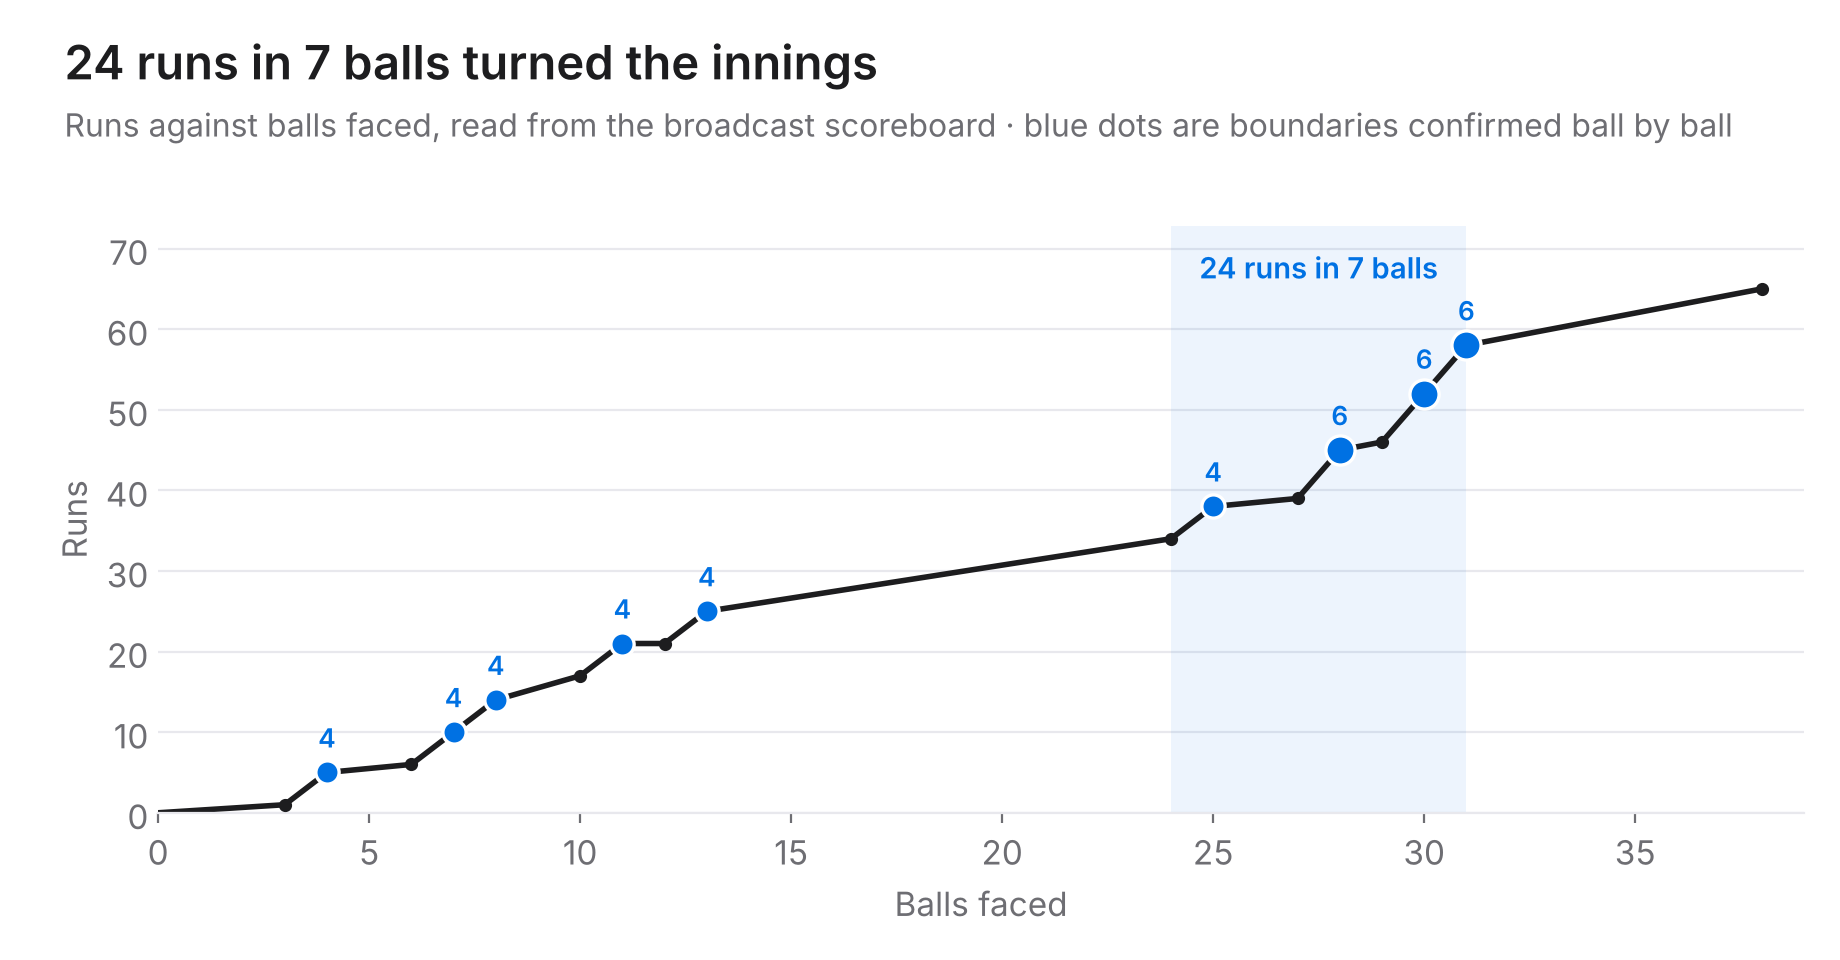

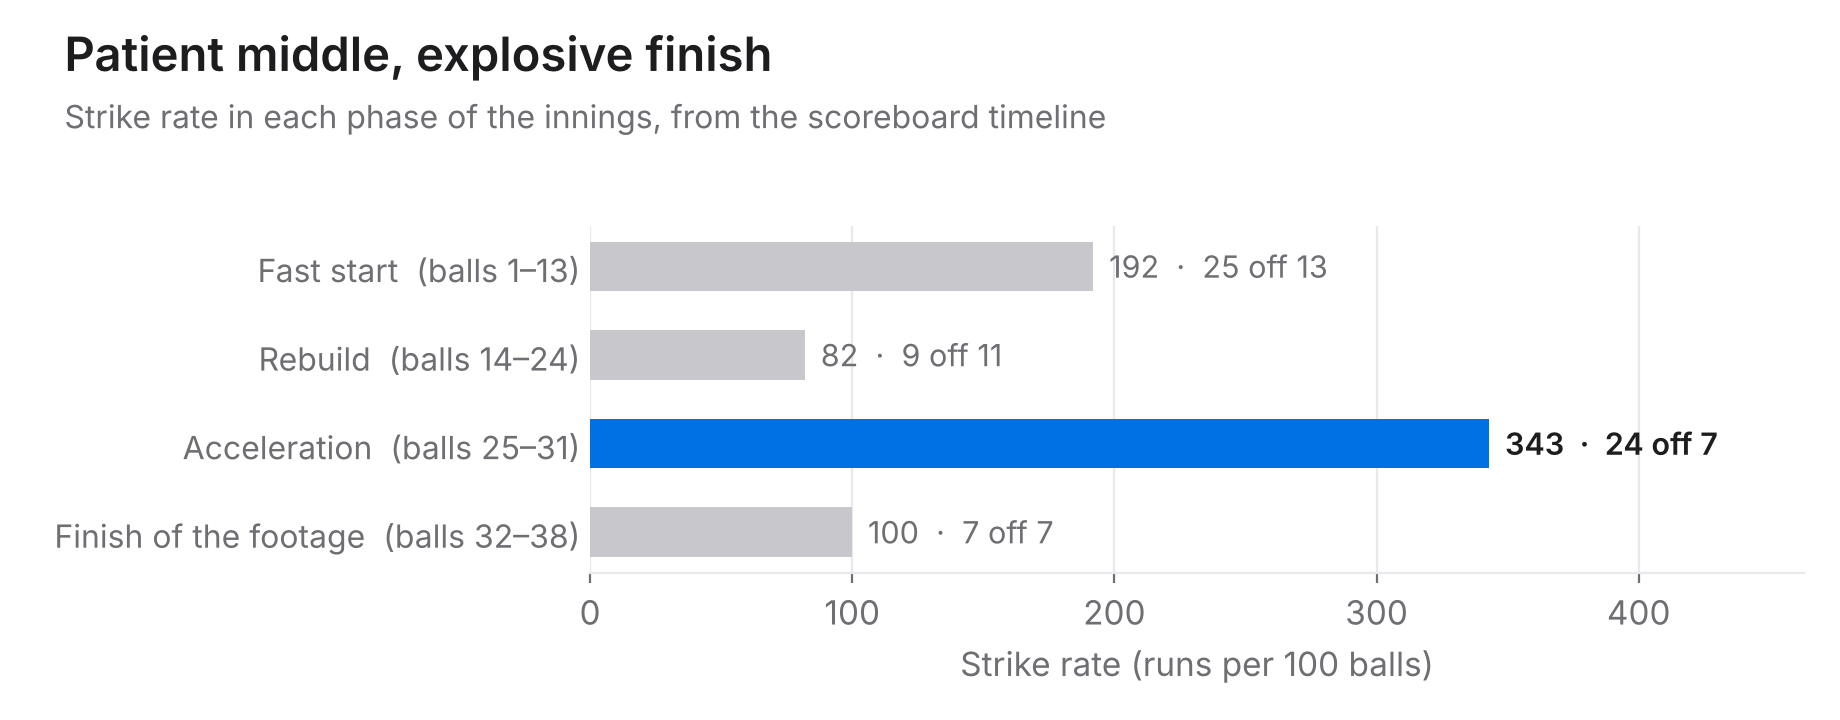

In [5]:
from IPython.display import Image, display
display(Image('figures/innings.png', width=900))
display(Image('figures/phases.png', width=900))

## 5 · How he moved

Nine strokes were tracked from the main camera. Each skeleton is centred on the hips and scaled to his height, so different camera zooms compare fairly. Spread = the average distance between the same body point across deliveries.

stance spread  7.6% of height
contact spread 18.2% of height  ->  2.4x more variation at contact
ball 4: 4
ball 7: 4
ball 8: 4
ball 11: 4
ball 13: 4
ball 25: 4
ball 28: 6
ball 30: 6
ball 39: outcome not in the footage


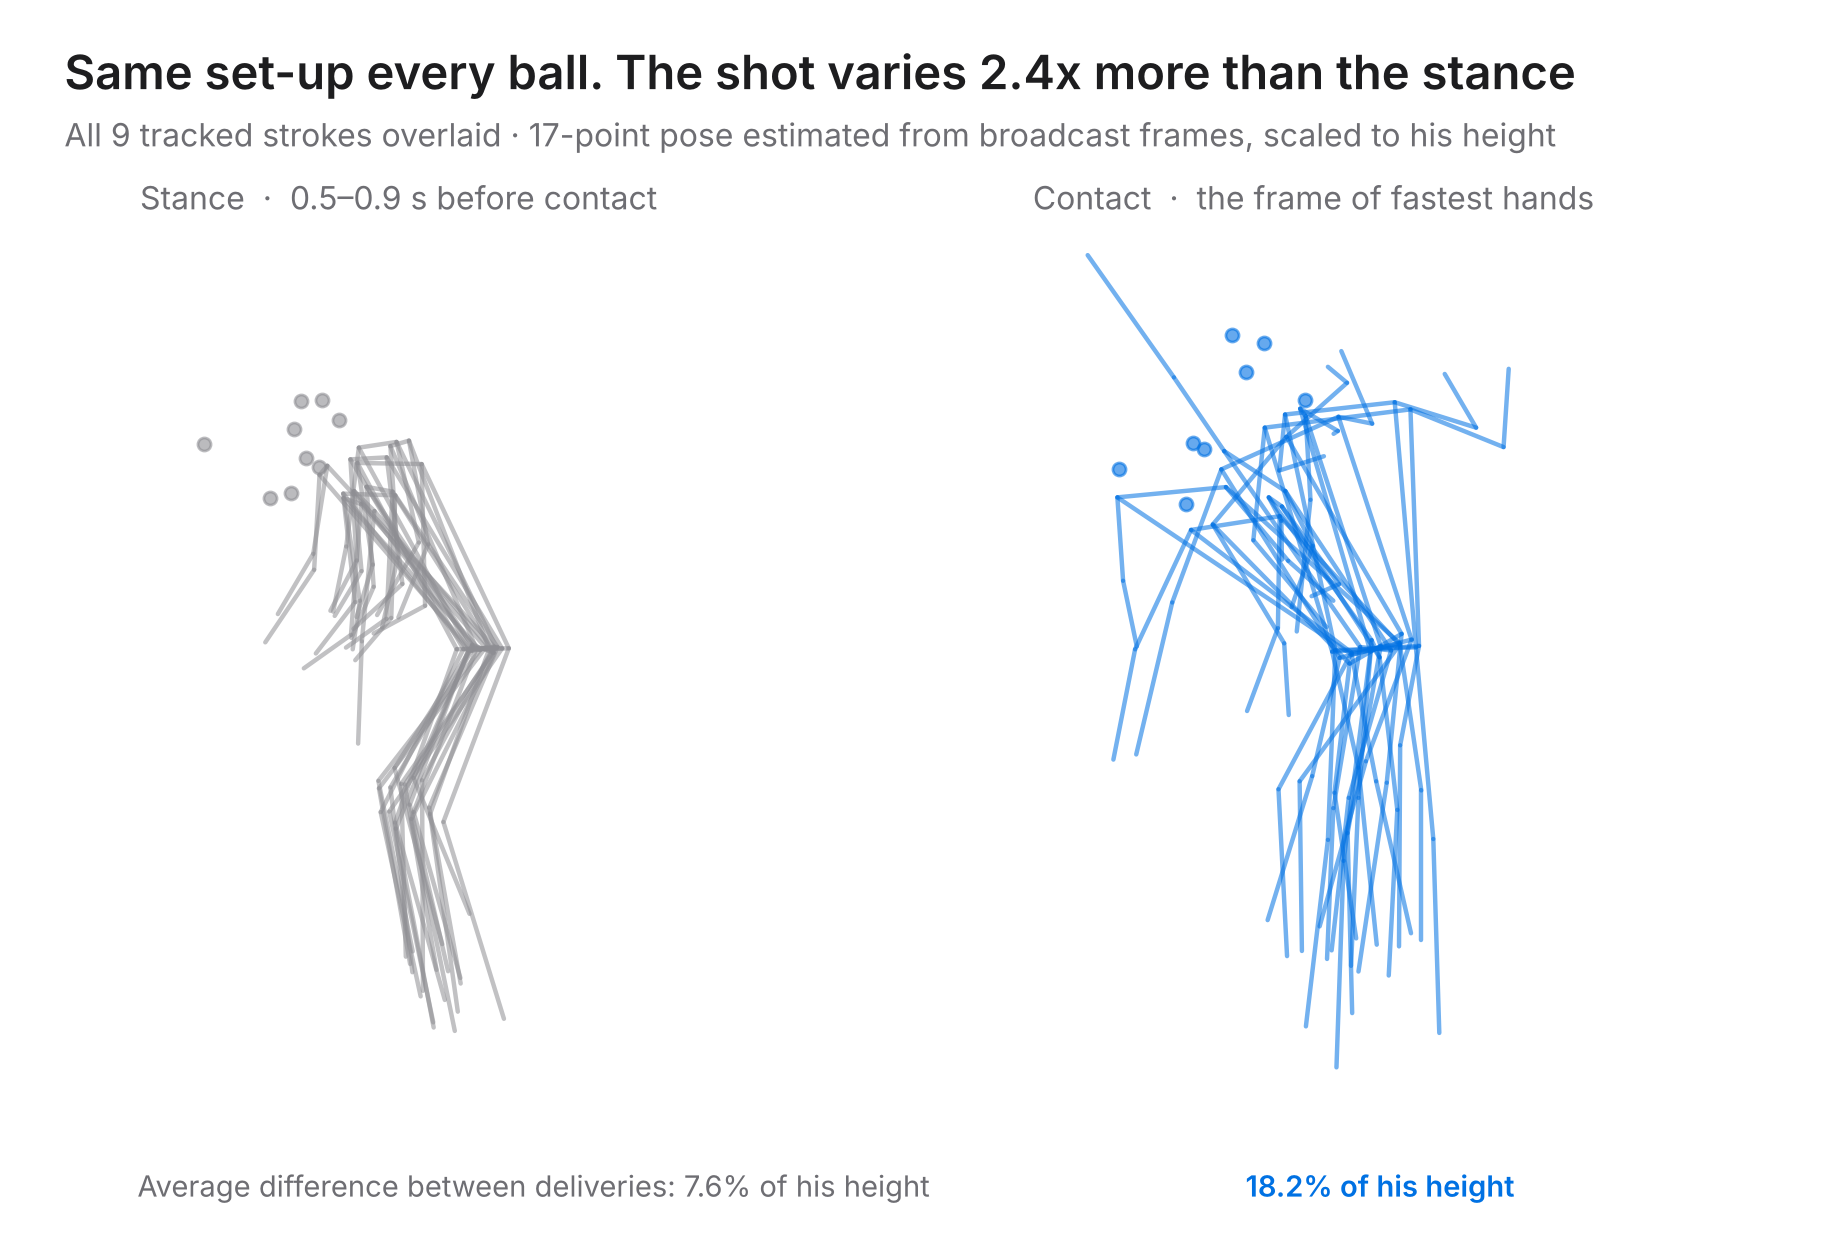

In [6]:
c = m['consistency']
print(f"stance spread  {c['stance_spread']*100:.1f}% of height")
print(f"contact spread {c['contact_spread']*100:.1f}% of height  ->  {c['ratio']}x more variation at contact")
for s in m['strokes']: print(f"ball {s['ball']}: {s['runs'] if s['runs'] is not None else 'outcome not in the footage'}")
display(Image('figures/strokes.png', width=900))

## 6 · What the computer found
- **24 runs in 7 balls** (balls 25–31) turned the innings: a four and three sixes in four balls.
- **Five fours in the first 13 balls**, then a rebuild of 9 off 11 while the opening stand ended.
- **At least 42 of the 65 runs** in the footage came from 9 boundaries confirmed ball by ball.
- **Same set-up every ball:** across 9 strokes his stance varies by 7.6% of his height; at contact the shapes vary 2.4 times more. The base stays fixed while the shot adapts to the ball.

## 7 · Limitations
- Highlights skip balls, so between some readings only the total for several balls is known.
- Pose comes from players about 150 pixels tall in broadcast video; it's good for overall body shape, not for fine joint angles.
- The nine strokes were checked by eye to confirm the tracked player is the striker; clips filmed from other angles were excluded.
- The broadcast's camera layout is hard-coded (scoreboard position, main camera geometry); another broadcast would need these set again.